# 01_Feature_Engineering — Table de modélisation

**Projet :** Credit Risk Scorecard · **Phase 2** — feature engineering SQL · Données : Home Credit Default Risk (Kaggle).

Prérequis : `scripts/build_features.py` a été exécuté (tables `feat_*`, `model_table_train`, `model_table_test` dans `database/credit_risk.duckdb`).
Ce notebook ouvre la base **en lecture seule** et contrôle le résultat : il ne crée aucune table.
**Aucune analyse ne fait intervenir `TARGET`** (D9) : la relation variables / cible est réservée à la Phase 3, après le split.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from build_features import MODEL_TABLES, SQL_STEPS, blocking_checks, count_by_prefix, sentinel_scan
from config import DB_PATH, FIGURES_DIR

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable : lancer scripts/load_to_database.py puis scripts/build_features.py")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique à 00_Data_Audit (fond clair, axes discrets, une seule teinte)
BLUE, INK, INK2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


## 1. Contrôle des sentinelles

Occurrences de la valeur 365243 dans toutes les colonnes `DAYS_*` des tables brutes. Seules les colonnes où elle apparaît sont traitées (→ NULL) en SQL :
`DAYS_EMPLOYED` des tables application (D1) et cinq colonnes de `previous_application`, avant agrégation (D2).
`bureau.DAYS_CREDIT_ENDDATE` contient des valeurs positives légitimes (échéance future) : elles ne sont pas traitées.

In [2]:
scan = sentinel_scan(con)
display(scan)
print(f"Colonnes contenant 365243 : {int((scan['n_365243'] > 0).sum())} sur {len(scan)} ; "
      f"toutes traitées : {bool((scan['n_365243'] > 0).eq(scan['traitee_en_sql']).all())}")

,table_name,colonne,n_365243,pct_lignes,traitee_en_sql
0,application_train,DAYS_BIRTH,0,0.00,False
1,application_train,DAYS_EMPLOYED,55374,18.01,True
2,application_train,DAYS_REGISTRATION,0,0.00,False
3,application_train,DAYS_ID_PUBLISH,0,0.00,False
4,application_train,DAYS_LAST_PHONE_CHANGE,0,0.00,False
5,application_test,DAYS_BIRTH,0,0.00,False
6,application_test,DAYS_EMPLOYED,9274,19.03,True
7,application_test,DAYS_REGISTRATION,0,0.00,False
8,application_test,DAYS_ID_PUBLISH,0,0.00,False
9,application_test,DAYS_LAST_PHONE_CHANGE,0,0.00,False


Colonnes contenant 365243 : 7 sur 22 ; toutes traitées : True


## 2. Volumétrie des tables d'agrégats

In [3]:
rows = []
for sql_file, tables in SQL_STEPS:
    for t in tables:
        n, n_cols = con.execute(f"SELECT COUNT(*), (SELECT COUNT(*) FROM (DESCRIBE {t})) FROM {t}").fetchone()
        key = "SK_ID_BUREAU" if t == "feat_bureau_balance_credit" else ("SK_ID_PREV" if t == "previous_application_clean" else "SK_ID_CURR")
        n_keys = con.execute(f"SELECT COUNT(DISTINCT {key}) FROM {t}").fetchone()[0]
        rows.append({"fichier": sql_file, "table_name": t, "grain": key, "n_rows": n, "n_cols": n_cols, "cle_unique": n_keys == n})
vol = pd.DataFrame(rows)
display(vol)

,fichier,table_name,grain,n_rows,n_cols,cle_unique
0,01_application_features.sql,application_all,SK_ID_CURR,356255,137,True
1,02_bureau_features.sql,feat_bureau_balance_credit,SK_ID_BUREAU,817395,9,True
2,02_bureau_features.sql,feat_bureau,SK_ID_CURR,305811,20,True
3,03_previous_application_features.sql,previous_application_clean,SK_ID_PREV,1670214,37,True
4,03_previous_application_features.sql,feat_previous_application,SK_ID_CURR,338857,16,True
5,04_installments_features.sql,feat_installments,SK_ID_CURR,339587,13,True
6,05_pos_cash_features.sql,feat_pos_cash,SK_ID_CURR,337252,9,True
7,06_credit_card_features.sql,feat_credit_card,SK_ID_CURR,103558,13,True
8,10_model_table.sql,model_table_train,SK_ID_CURR,307511,208,True
9,10_model_table.sql,model_table_test,SK_ID_CURR,48744,207,True


Chaque table d'agrégats a exactement une ligne par clé de grain (`cle_unique`) : la jointure gauche sur `application_all` ne peut pas dupliquer de demande.
`feat_bureau_balance_credit` (1 ligne par crédit externe) ne compte que les `SK_ID_BUREAU` présents dans `bureau_balance` ; les orphelins disparaissent à la jointure avec `bureau` (D5).

## 3. Contrôles bloquants de la table modèle

In [4]:
checks = blocking_checks(con)
display(checks)
print("Tous les contrôles bloquants :", "OK" if checks["ok"].all() else "ÉCHEC")

,controle,resultat,ok
0,model_table_train : lignes = application_train...,"307,511 / 307,511 attendues",True
1,model_table_train : SK_ID_CURR unique,"307,511 distincts / 307,511 lignes",True
2,model_table_test : lignes = application_test (...,"48,744 / 48,744 attendues",True
3,model_table_test : SK_ID_CURR unique,"48,744 distincts / 48,744 lignes",True
4,TARGET présente et sans NULL (train),"présente : True, NULL : 0",True
5,"TARGET ∈ {0, 1} (train)","0 valeur(s) hors {0, 1}",True
6,TARGET absente (test),présente : False,True
7,model_table_train : aucune valeur infinie ni N...,0 valeur(s),True
8,model_table_test : aucune valeur infinie ni Na...,0 valeur(s),True
9,application_all.DAYS_EMPLOYED : aucune valeur ...,0 valeur(s),True


Tous les contrôles bloquants : OK


## 4. Nombre de variables par famille

In [5]:
fam = count_by_prefix(con)
display(fam)
n_created = int(fam.loc[fam["famille"] == "total créées", "n_variables"].iloc[0])
print(f"Variables créées : {n_created} (86 validées, D13 amendé le 29/09) → "
      + ("conforme" if n_created == 86 else "ÉCART : mettre à jour le catalogue et le cahier"))

,famille,n_variables
0,APP_,14
1,BUR_,11
2,BB_,8
3,PREV_,15
4,INS_,12
5,POS_,8
6,CC_,12
7,HAS_,6
8,total créées,86
9,brutes (application),120


Variables créées : 86 (86 validées, D13 amendé le 29/09) → conforme


## 5. Distribution des taux de manquants (`model_table_train`, hors `TARGET`)

Taux de manquants de chaque colonne, variables créées et colonnes brutes séparées. D7 : une statistique d'historique est NULL quand le client n'a pas d'historique dans la source.

type,brute,créée
tranche,,
0 %,52,27
]0 ; 10 %],10,21
]10 ; 50 %],17,20
> 50 %,41,18


**Variables créées les plus lacunaires**

,colonne,pct_manquants,type,tranche
0,CC_MEAN_UTILIZATION_12M,76.807009,créée,> 50 %
1,CC_MAX_UTILIZATION_12M,76.807009,créée,> 50 %
2,BB_MEAN_SHARE_MONTHS_LATE_12M,76.380032,créée,> 50 %
3,BB_MAX_SHARE_MONTHS_LATE_12M,76.380032,créée,> 50 %
4,BB_MAX_STATUS_12M,76.380032,créée,> 50 %
5,CC_MEAN_UTILIZATION,72.021814,créée,> 50 %
6,CC_MAX_UTILIZATION,72.021814,créée,> 50 %
7,CC_SHARE_MONTHS_DPD_12M,71.739222,créée,> 50 %
8,CC_MEAN_DRAWINGS,71.739222,créée,> 50 %
9,CC_MEAN_DRAWINGS_12M,71.739222,créée,> 50 %


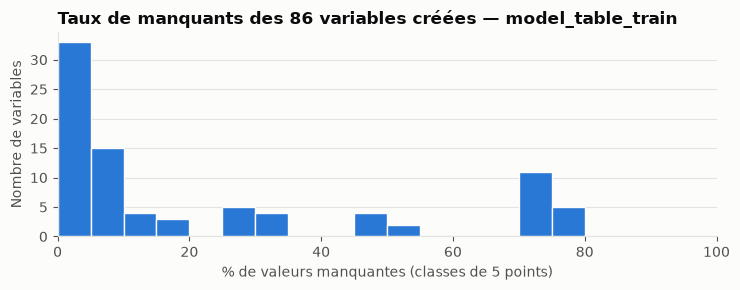

In [6]:
cols = [c for c, in con.execute("SELECT column_name FROM (DESCRIBE model_table_train)").fetchall()
        if c not in ("SK_ID_CURR", "TARGET")]
expr = ", ".join(f'100.0 * COUNT(*) FILTER (WHERE "{c}" IS NULL) / COUNT(*)' for c in cols)
miss = pd.DataFrame({"colonne": cols, "pct_manquants": con.execute(f"SELECT {expr} FROM model_table_train").fetchone()})
created_prefixes = ("APP_", "BUR_", "BB_", "PREV_", "INS_", "POS_", "CC_", "HAS_")
miss["type"] = miss["colonne"].map(lambda c: "créée" if c.startswith(created_prefixes) else "brute")
bins = [-0.001, 0, 10, 50, 100]
labels = ["0 %", "]0 ; 10 %]", "]10 ; 50 %]", "> 50 %"]
miss["tranche"] = pd.cut(miss["pct_manquants"], bins=bins, labels=labels)
synth = miss.pivot_table(index="tranche", columns="type", values="colonne", aggfunc="count", observed=False).fillna(0).astype(int)
display(synth)
display(Markdown("**Variables créées les plus lacunaires**"))
display(miss.query("type == 'créée'").sort_values("pct_manquants", ascending=False).head(12).reset_index(drop=True))

created = miss.query("type == 'créée'").sort_values("pct_manquants")
fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.hist(created["pct_manquants"], bins=range(0, 105, 5), color=BLUE, edgecolor="#fcfcfb")
ax.set_xlim(0, 100)
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title(f"Taux de manquants des {len(created)} variables créées — model_table_train", loc="left")
ax.set_xlabel("% de valeurs manquantes (classes de 5 points)")
ax.set_ylabel("Nombre de variables")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_missing_created_features.png", dpi=150)
plt.show()

Les pics correspondent aux sources : une variable de statistique hérite du taux d'absence d'historique de sa table (par exemple `credit_card_balance`),
et les fenêtres `_12M` sont plus lacunaires que l'historique complet. Les comptages (`*_NB_*`) et les `HAS_*` n'ont aucun manquant (D7).

## 6. Couverture des historiques (`HAS_*_HISTORY`, train)

,indicateur,pct_train
0,HAS_INS_HISTORY,94.84
1,HAS_PREV_HISTORY,94.65
2,HAS_POS_HISTORY,94.12
3,HAS_BUR_HISTORY,85.69
4,HAS_BB_HISTORY,29.99
5,HAS_CC_HISTORY,28.26


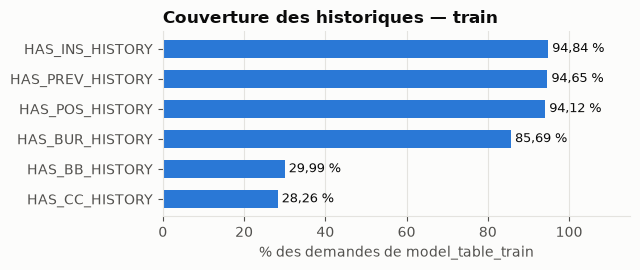

In [7]:
has_cols = [c for c in cols if c.startswith("HAS_")]
cov = con.execute("SELECT " + ", ".join(f"100.0 * AVG({c})" for c in has_cols) + " FROM model_table_train").fetchone()
coverage = pd.DataFrame({"indicateur": has_cols, "pct_train": [round(v, 2) for v in cov]}).sort_values("pct_train", ascending=False, ignore_index=True)
display(coverage)

fig, ax = plt.subplots(figsize=(6.5, 2.8))
bars = ax.barh(coverage["indicateur"], coverage["pct_train"], color=BLUE, height=0.6)
for b, p in zip(bars, coverage["pct_train"]):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{p:.2f} %".replace(".", ","), va="center", fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Couverture des historiques — train", loc="left")
ax.set_xlabel("% des demandes de model_table_train")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_history_coverage.png", dpi=150)
plt.show()

## 7. Synthèse et points à surveiller pour la Phase 3
Chiffres calculés ci-dessous à partir des contrôles exécutés.

In [8]:
g = lambda n: f"{n:,}".replace(",", " ")
p = lambda x: f"{x:.2f}".replace(".", ",")
n_train, n_test = (con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in MODEL_TABLES)
n_cols_train = len(cols) + 2
cv = coverage.set_index("indicateur")["pct_train"]
fam_s = fam.set_index("famille")["n_variables"]
worst = miss.query("type == 'créée'").sort_values("pct_manquants", ascending=False).iloc[0]
neg_debt = con.execute("SELECT COUNT(*) FILTER (WHERE BUR_SUM_DEBT < 0), COUNT(*) FILTER (WHERE BUR_DEBT_CREDIT_RATIO > 1) FROM model_table_train").fetchone()
anom = con.execute("SELECT SUM(APP_FLAG_DAYS_EMPLOYED_ANOM), COUNT(*) FILTER (WHERE APP_FLAG_DAYS_EMPLOYED_ANOM = 1 AND NAME_INCOME_TYPE = 'Pensioner') FROM model_table_train").fetchone()

display(Markdown(f"""
**Constats**
- Table modèle : `model_table_train` {g(n_train)} lignes × {n_cols_train} colonnes, `model_table_test` {g(n_test)} lignes × {n_cols_train - 1} colonnes (sans `TARGET`) ; {"tous les contrôles bloquants sont satisfaits" if checks["ok"].all() else "contrôle(s) en échec"}.
- Variables créées : **{n_created}** (`APP_` {fam_s["APP_"]}, `BUR_` {fam_s["BUR_"]}, `BB_` {fam_s["BB_"]}, `PREV_` {fam_s["PREV_"]}, `INS_` {fam_s["INS_"]}, `POS_` {fam_s["POS_"]}, `CC_` {fam_s["CC_"]}, `HAS_` {fam_s["HAS_"]}), plus {fam_s["brutes (application)"]} colonnes brutes. Volume accepté (D13 amendé le 29/09 ; cadre indicatif initial : 100 à 200).
- Couverture du train : demandes antérieures {p(cv["HAS_PREV_HISTORY"])} %, échéances {p(cv["HAS_INS_HISTORY"])} %, POS {p(cv["HAS_POS_HISTORY"])} %, bureau {p(cv["HAS_BUR_HISTORY"])} %, historique mensuel du bureau {p(cv["HAS_BB_HISTORY"])} %, cartes {p(cv["HAS_CC_HISTORY"])} %.
- Variable créée la plus lacunaire : `{worst["colonne"]}` ({p(worst["pct_manquants"])} %).

**Points à surveiller en Phase 3**
1. `APP_FLAG_DAYS_EMPLOYED_ANOM` : {g(int(anom[0]))} demandes, dont {g(int(anom[1]))} retraités (`NAME_INCOME_TYPE = 'Pensioner'`) → colinéarité à contrôler au VIF (D1).
2. Colonnes `DAYS_*` brutes et `APP_*_YEARS` : même information à une transformation linéaire près ; les `DAYS_*` sont marquées « exclues du modèle » dans le catalogue.
3. Doublons structurels : triplets logement `*_AVG` / `*_MODE` / `*_MEDI`, couples historique complet / `_12M` → filtrés par la corrélation des WoE (< 0,7).
4. Valeurs atypiques héritées des sources : {g(neg_debt[0])} demandes avec `BUR_SUM_DEBT` négatif, {g(neg_debt[1])} avec `BUR_DEBT_CREDIT_RATIO` > 1 ; le binning optimal les isolera sans suppression.
5. Faible couverture des cartes ({p(cv["HAS_CC_HISTORY"])} %) et de l'historique mensuel du bureau ({p(cv["HAS_BB_HISTORY"])} %, contre {p(cv["HAS_BUR_HISTORY"])} % pour `bureau`) : les variables `CC_` et `BB_` (hors comptages) sont NULL pour la majorité des demandes ; le manquant devient une classe du binning (D7).
6. Toute analyse faisant intervenir `TARGET` (taux de défaut par segment, IV) se fait après le split 70/15/15, sur le train seul (D9).
"""))


**Constats**
- Table modèle : `model_table_train` 307 511 lignes × 208 colonnes, `model_table_test` 48 744 lignes × 207 colonnes (sans `TARGET`) ; tous les contrôles bloquants sont satisfaits.
- Variables créées : **86** (`APP_` 14, `BUR_` 11, `BB_` 8, `PREV_` 15, `INS_` 12, `POS_` 8, `CC_` 12, `HAS_` 6), plus 120 colonnes brutes. Volume accepté (D13 amendé le 29/09 ; cadre indicatif initial : 100 à 200).
- Couverture du train : demandes antérieures 94,65 %, échéances 94,84 %, POS 94,12 %, bureau 85,69 %, historique mensuel du bureau 29,99 %, cartes 28,26 %.
- Variable créée la plus lacunaire : `CC_MEAN_UTILIZATION_12M` (76,81 %).

**Points à surveiller en Phase 3**
1. `APP_FLAG_DAYS_EMPLOYED_ANOM` : 55 374 demandes, dont 55 352 retraités (`NAME_INCOME_TYPE = 'Pensioner'`) → colinéarité à contrôler au VIF (D1).
2. Colonnes `DAYS_*` brutes et `APP_*_YEARS` : même information à une transformation linéaire près ; les `DAYS_*` sont marquées « exclues du modèle » dans le catalogue.
3. Doublons structurels : triplets logement `*_AVG` / `*_MODE` / `*_MEDI`, couples historique complet / `_12M` → filtrés par la corrélation des WoE (< 0,7).
4. Valeurs atypiques héritées des sources : 1 091 demandes avec `BUR_SUM_DEBT` négatif, 5 158 avec `BUR_DEBT_CREDIT_RATIO` > 1 ; le binning optimal les isolera sans suppression.
5. Faible couverture des cartes (28,26 %) et de l'historique mensuel du bureau (29,99 %, contre 85,69 % pour `bureau`) : les variables `CC_` et `BB_` (hors comptages) sont NULL pour la majorité des demandes ; le manquant devient une classe du binning (D7).
6. Toute analyse faisant intervenir `TARGET` (taux de défaut par segment, IV) se fait après le split 70/15/15, sur le train seul (D9).


In [9]:
con.close()